# Solutions

In [18]:
import hashlib

import matplotlib.pyplot as plt
import numpy as np

# The photos are stored in the course repository
BASE = "https://raw.githubusercontent.com/daniprec/Python-Course/main/data/ghost_photos"


def show(image):
    """Display an image: a 2D array (grayscale, 0 = black, 1 = white) or a 3D array (colour)."""
    if image.ndim == 2:
        plt.imshow(image, cmap="gray", vmin=0, vmax=1)
    else:
        plt.imshow(np.clip(image, 0, 1))
    plt.axis("off")
    plt.show()


_KEYS = {
    1: "acba8dd74b724348",
    2: "f5ca38f748a1d6ea",
    3: "9ae2bdd7beedc2e7",
    4: "d4735e3a265e16ee",
    5: "72440a20f54075ac",
    "case": "cc4a9135117f2dbf",
}


def check(photo, key):
    """Check the key of a photo (1 to 5) or of the case ("case")."""
    digest = hashlib.sha256(str(key).strip().upper().encode()).hexdigest()[:16]
    if digest != _KEYS[photo]:
        print(f"Wrong key for photo {photo}. Keep investigating...")
    elif photo == "case":
        print("Correct case number! The ghost hunt is solved.")
    else:
        print(f"Correct key! Photo {photo} is recovered.")

## Photo 1: The Shattered Photo

In [19]:
filenames = [f"fragment_{letter}.txt" for letter in "ABCDEFGHI"]
print(filenames)

['fragment_A.txt', 'fragment_B.txt', 'fragment_C.txt', 'fragment_D.txt', 'fragment_E.txt', 'fragment_F.txt', 'fragment_G.txt', 'fragment_H.txt', 'fragment_I.txt']


Load one fragment and look at its top-left pixel:

(100, 100)
Fragment number: 5.0


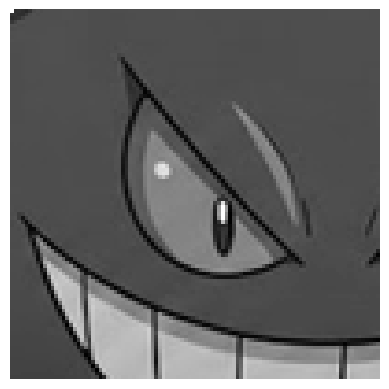

In [20]:
fragment = np.loadtxt(f"{BASE}/photo_1/{filenames[0]}")
print(fragment.shape)
print("Fragment number:", fragment[0, 0])
show(fragment)

Load every fragment and read its number:

In [21]:
fragments = []
numbers = []

for name in filenames:
    fragment = np.loadtxt(f"{BASE}/photo_1/{name}")
    fragments.append(fragment)
    numbers.append(fragment[0, 0])

numbers = np.array(numbers)
print(numbers)

[5. 8. 1. 6. 9. 3. 2. 7. 4.]


`np.argsort()` gives the positions that sort the fragment numbers. The key is the letters in that order.

In [22]:
order = np.argsort(numbers)
print(order)

key = "".join(filenames[i][9] for i in order)  # "fragment_X.txt" -> "X"
print(key)
check(1, key)

sorted_fragments = [fragments[i] for i in order]

[2 6 5 8 0 3 7 1 4]
CGFIADHBE
Correct key! Photo 1 is recovered.


Join each row of three fragments side by side (`axis=1`), then the three rows one on top of the other (`axis=0`):

(300, 300)


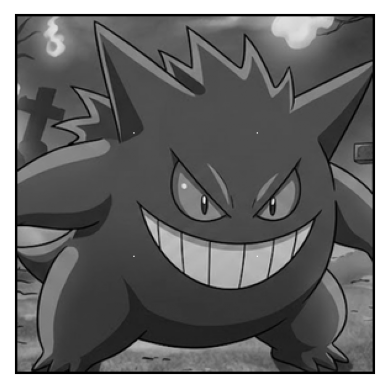

In [23]:
row_0 = np.concatenate(sorted_fragments[0:3], axis=1)
row_1 = np.concatenate(sorted_fragments[3:6], axis=1)
row_2 = np.concatenate(sorted_fragments[6:9], axis=1)

photo_1 = np.concatenate((row_0, row_1, row_2), axis=0)
print(photo_1.shape)
show(photo_1)

The white dots in the corners of the fragments are the fragment numbers: values above 1 are shown as white.

## Photo 2: The Frozen Photo

In [24]:
fragment = np.loadtxt(f"{BASE}/photo_2/fragment_0_0.txt")
print(fragment.shape)

(10000,)


Each fragment is a $100 \times 100$ square flattened into 10,000 values: `reshape()` gives it back its shape.

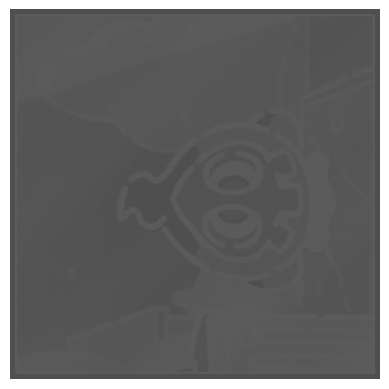

0.31 0.36


In [25]:
rows = []

for r in range(3):
    row_fragments = []
    for c in range(3):
        fragment = np.loadtxt(f"{BASE}/photo_2/fragment_{r}_{c}.txt")
        row_fragments.append(fragment.reshape(100, 100))
    rows.append(np.concatenate(row_fragments, axis=1))

stored = np.concatenate(rows, axis=0)
show(stored)
print(stored.min(), stored.max())

Stretch the values back to $[0, 1]$:

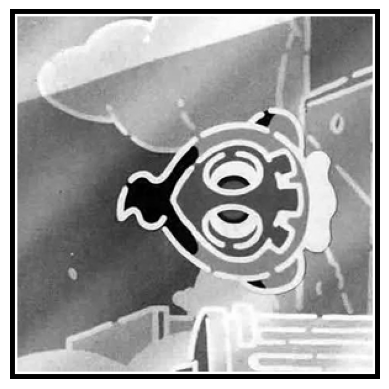

In [26]:
stretched = (stored - stored.min()) / (stored.max() - stored.min())
show(stretched)

A negative, mirrored along the diagonal. Undo both:

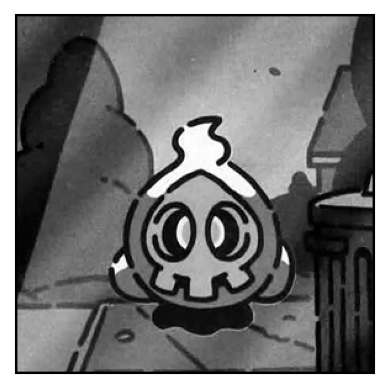

20
Correct key! Photo 2 is recovered.


In [27]:
photo_2 = (1 - stretched).T
show(photo_2)

key = round(1 / (stored.max() - stored.min()))
print(key)
check(2, key)

## Photo 3: The Banded Photo

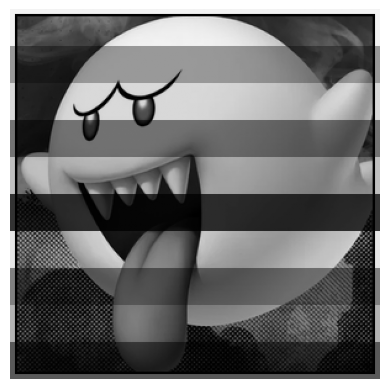

In [28]:
rows = []

for r in range(3):
    row_fragments = []
    for c in range(3):
        fragment = np.loadtxt(f"{BASE}/photo_3/fragment_{r}_{c}.csv", delimiter=";")
        row_fragments.append(fragment)
    rows.append(np.concatenate(row_fragments, axis=1))

stored = np.concatenate(rows, axis=0)
show(stored)

The first column of the original photo is the white frame (all `1`), so the first column of `stored` is the gain of each row:

In [29]:
gain = stored[:, 0]
print(gain.shape)
print(gain[:40])

(300,)
[0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95
 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95 0.95
 0.95 0.95 0.6  0.6  0.6  0.6  0.6  0.6  0.6  0.6  0.6  0.6 ]


`gain` has shape `(300,)`, so broadcasting treats it as a **row** and divides the columns. We need a column, `(300, 1)`, to divide the rows:

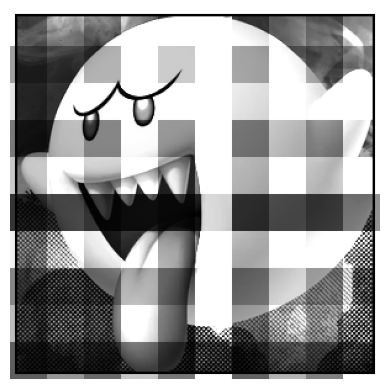

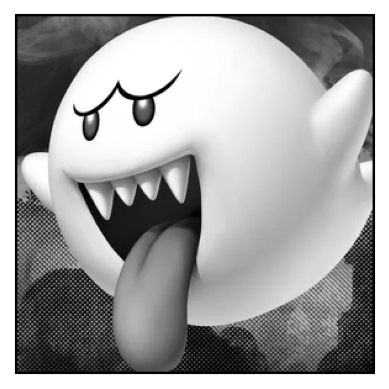

150
Correct key! Photo 3 is recovered.


In [30]:
show(stored / gain)  # wrong: divides each column

photo_3 = stored / gain.reshape(-1, 1)  # right: divides each row
show(photo_3)

key = np.argmin(gain)
print(key)
check(3, key)

The bands are also visible in the mean of each row (`axis=1`):

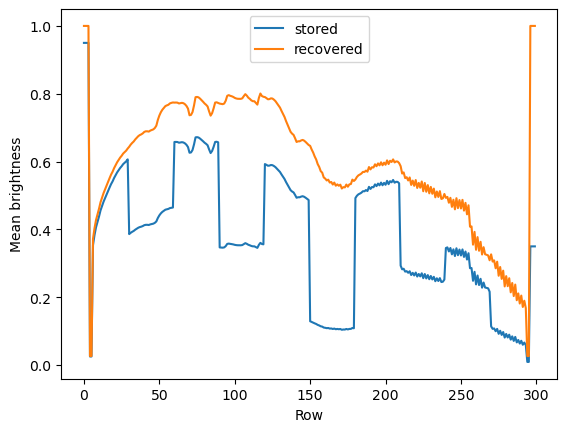

In [31]:
plt.plot(np.mean(stored, axis=1), label="stored")
plt.plot(np.mean(photo_3, axis=1), label="recovered")
plt.xlabel("Row")
plt.ylabel("Mean brightness")
plt.legend()
plt.show()

## Photo 4: The Cursed Lens

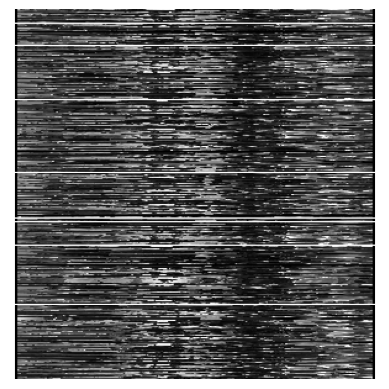

In [32]:
rows = []

for r in range(3):
    row_fragments = [
        np.loadtxt(f"{BASE}/photo_4/fragment_{r}_{c}.csv", delimiter=",")
        for c in range(3)
    ]
    rows.append(np.hstack(row_fragments))

stored = np.vstack(rows)
show(stored)

`np.hstack()` and `np.vstack()` do the same as `np.concatenate()` with `axis=1` and `axis=0`. Now, the lenses:

In [33]:
lenses = {}

for k in range(1, 4):
    L = np.loadtxt(f"{BASE}/photo_4/lens_{k}.csv", delimiter=",")
    lenses[k] = L
    print(f"lens_{k}: shape {L.shape}, determinant {np.linalg.det(L):.1f}")

lens_1: shape (300, 300), determinant 0.0
lens_2: shape (300, 300), determinant -1.0
lens_3: shape (300, 300), determinant 0.0


Lenses 1 and 3 have determinant 0: they have no inverse.

In [34]:
np.linalg.inv(lenses[1])

LinAlgError: Singular matrix

Correct key! Photo 4 is recovered.


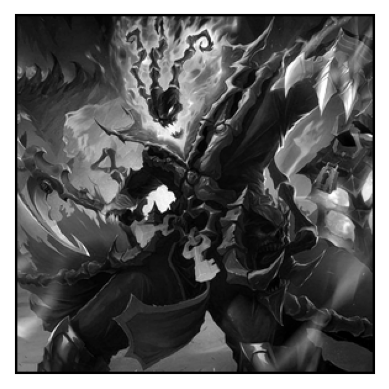

In [ ]:
key = 2
check(4, key)

L = lenses[key]
photo_4 = np.linalg.inv(L) @ stored
show(photo_4)

`L` only moves rows around, so its inverse is its transpose:

In [ ]:
print(np.allclose(np.linalg.inv(L), L.T))
print(np.allclose(L.T @ stored, photo_4))

True
True


## Photo 5: The Colour Photo

1 (300, 300)


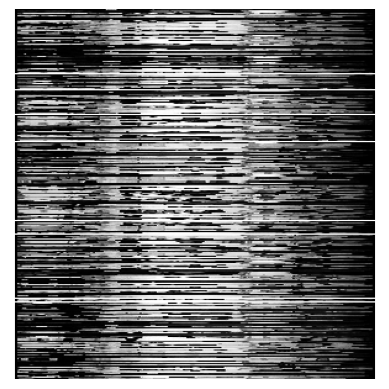

2 (300, 300)


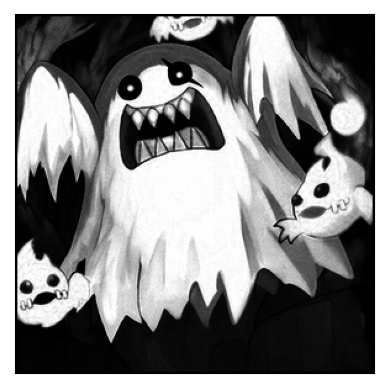

3 (300, 300)


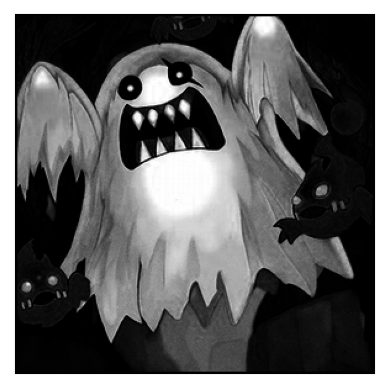

4 (300, 300)


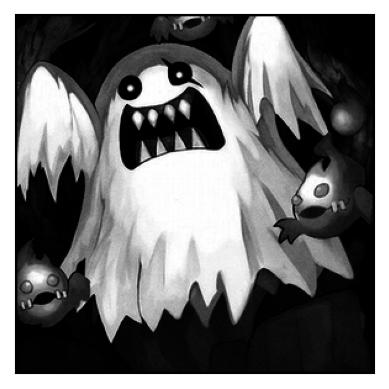

In [ ]:
channels = {}

for k in range(1, 5):
    channels[k] = np.loadtxt(f"{BASE}/photo_5/channel_{k}.txt")
    print(k, channels[k].shape)
    show(channels[k])

Channel 1 is static: the decoy. The other three are channels of the photo. Try one order, undo the square, and look:

(300, 300, 3)


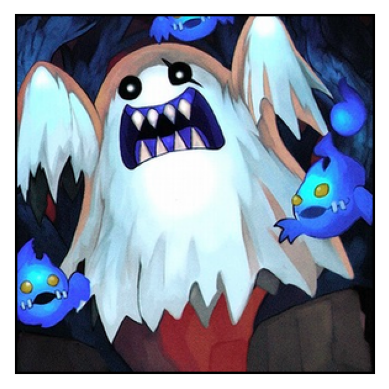

In [ ]:
attempt = np.sqrt(np.stack((channels[3], channels[4], channels[2]), axis=2))
print(attempt.shape)
show(attempt)

Blue flames? A will-o'-the-wisp, not our ghost: wrong order. With three channels there are only $3 \times 2 \times 1 = 6$ possible orders, so we can try them all:

red: 2 green: 3 blue: 4


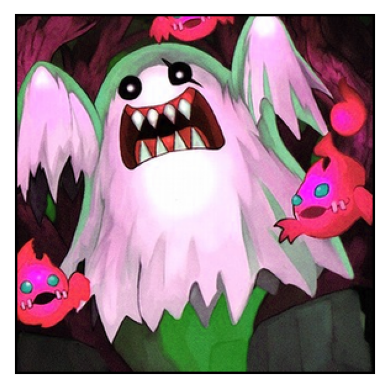

red: 2 green: 4 blue: 3


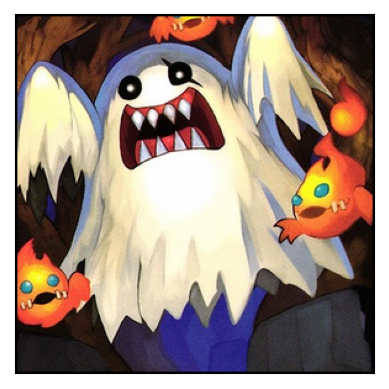

red: 3 green: 2 blue: 4


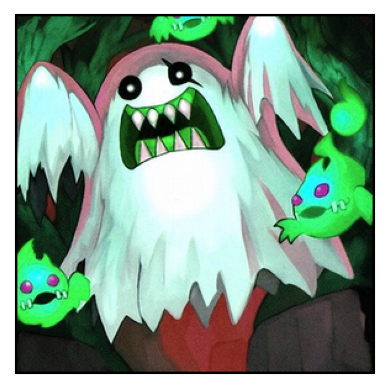

red: 3 green: 4 blue: 2


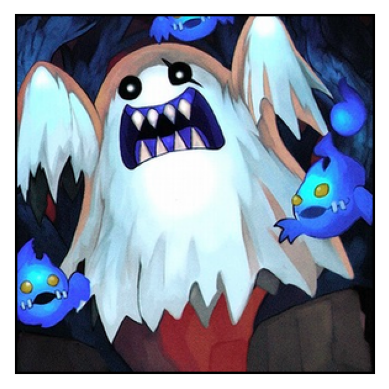

red: 4 green: 2 blue: 3


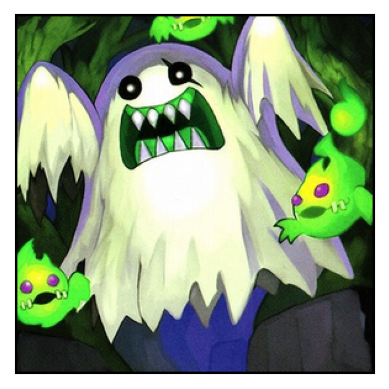

red: 4 green: 3 blue: 2


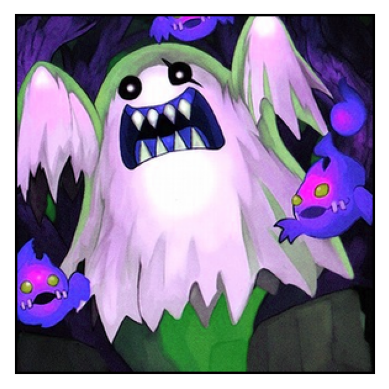

In [ ]:
orders = [(2, 3, 4), (2, 4, 3), (3, 2, 4), (3, 4, 2), (4, 2, 3), (4, 3, 2)]

for red, green, blue in orders:
    print("red:", red, "green:", green, "blue:", blue)
    show(np.sqrt(np.stack((channels[red], channels[green], channels[blue]), axis=2)))

Only one order shows orange flames, as the camera log said:

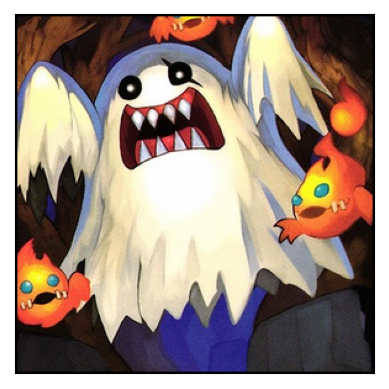

Correct key! Photo 5 is recovered.


In [ ]:
photo_5 = np.sqrt(np.stack((channels[2], channels[4], channels[3]), axis=2))
show(photo_5)
check(5, "243")

## The Case Number

The digit of each photo is the first decimal of the mean of its top-right quarter. For the colour photo, only the red channel (index 0 of the last axis).

In [ ]:
quarters = [
    photo_1[:150, 150:],
    photo_2[:150, 150:],
    photo_3[:150, 150:],
    photo_4[:150, 150:],
    photo_5[:150, 150:, 0],
]

case = ""
for quarter in quarters:
    mean = np.mean(quarter)
    digit = int(mean * 10)
    print(f"mean {mean:.4f} -> digit {digit}")
    case = case + str(digit)

print(case)
check("case", case)

mean 0.3768 -> digit 3
mean 0.5464 -> digit 5
mean 0.7409 -> digit 7
mean 0.3358 -> digit 3
mean 0.6144 -> digit 6
35736
Correct case number! The ghost hunt is solved.


A half-fixed photo gives a different digit. For instance, photo 2 without the transpose:

In [ ]:
print(int(np.mean((1 - stretched)[:150, 150:]) * 10))

3


## Save the Evidence

In [ ]:
np.save("photo_1.npy", photo_1)
np.savetxt("photo_1.txt", photo_1, fmt="%.4f")
np.save("photo_5.npy", photo_5)

print(np.allclose(np.load("photo_1.npy"), photo_1))
print(np.allclose(np.loadtxt("photo_1.txt"), photo_1))
print(np.load("photo_5.npy").shape)  # .npy keeps the 3D shape

True
True
(300, 300, 3)


`np.savetxt()` only accepts 1D and 2D arrays, so it fails with the colour photo:

In [ ]:
np.savetxt("photo_5.txt", photo_5)

ValueError: Expected 1D or 2D array, got 3D array instead

---

## Summary and Reflection

- `np.loadtxt()` loads text files, even straight from a URL; `delimiter` sets the separator of CSV files.
- `np.load()` loads `.npy` files from your computer.
- `np.save()` keeps an array exactly, with its shape and data type; `np.savetxt()` writes readable text, but only for 1D and 2D arrays.
- `np.concatenate()`, `np.hstack()`, and `np.vstack()` join arrays along an existing axis; `np.stack()` creates a new one.
- Array arithmetic, broadcasting, aggregations, and matrix operations can undo many transformations, as long as we know what happened.

Which photo was the hardest to recover, and why? For each photo, how did you know that your result was correct?